# Which Texas Bird Is It? · Notebook 2: Modeling and Evaluation

**DATA 4380 · Alejandro Alfonso, Tej Govindu, Mateen Jan**

We build up the model **one change at a time** and measure each change on the **validation set**, so every gain can be credited to a specific decision:

| Step | Model | The one thing that changes |
|---|---|---|
| 0 | Majority-class guess | Nothing learned: always predicts the most common species |
| 1 | **Baseline:** simple CNN | Minimum preprocessing only (128 px, pixels scaled to 0–1) |
| 2 | Simple CNN **+ augmentation** | Random flip / rotation / zoom / contrast on training images |
| 3 | **MobileNetV2, frozen** (transfer learning) | Pretrained ImageNet features instead of learning from scratch |
| 3b | MobileNetV2, frozen, **no augmentation** | Check: does augmentation help the pretrained model? |
| 4 | **MobileNetV2, fine-tuned** | Top 30 layers unfrozen, learning rate 1e-5 |
| 5 | **Tuned** fine-tuning | Number of unfrozen layers × learning rate, chosen on validation only |

The **test set is not used for any decision**. All models are scored on it only at the end, for the comparison table.

### Glossary

| Term | Meaning |
|---|---|
| **CNN (convolutional neural network)** | A neural network for images. *Convolution* layers slide small filters over the image to detect edges, then textures, then parts like beaks or wings. |
| **Pooling** | Shrinks the image after a convolution, keeping the strongest signals. |
| **Dropout** | Randomly switches off some neurons during training so the model can't rely on any single one; reduces overfitting. |
| **Softmax** | The final layer; turns scores into 10 probabilities that add up to 100%. |
| **Epoch** | One full pass through all training images. |
| **Loss** | How wrong the model is (we use *cross-entropy*). Training tries to make it smaller. |
| **Overfitting** | The model memorizes training images and does worse on new ones: training accuracy keeps rising while validation accuracy stalls. |
| **Early stopping** | Stops training when validation loss stops improving and keeps the best version. |
| **Augmentation** | Random small changes to training images so the model sees more variety. |
| **Transfer learning** | Starting from a model already trained on a huge dataset (ImageNet: 1.4 million photos, 1,000 categories) instead of from random weights. |
| **MobileNetV2** | A small, fast pretrained CNN (about 2.3 million weights without its top layer) designed for phones, so it trains quickly on a laptop. |
| **Frozen / fine-tuning** | *Frozen* layers keep their pretrained weights. *Fine-tuning* unfreezes some layers and retrains them with a very small learning rate. |
| **Learning rate** | How big a step the model takes when updating its weights. |
| **Hyperparameter** | A setting we choose rather than the model learning it (e.g., learning rate, number of unfrozen layers). |
| **Accuracy** | Share of images labeled correctly. |
| **Precision / recall / F1** | Per species: *precision* = of the images we called "Crow", how many were crows; *recall* = of the real crows, how many we found; *F1* = their balance. |
| **Macro average** | The average over the 10 species, each counted equally. |
| **ROC-AUC (one-vs-rest)** | For each species, how well the model ranks that species above the others (0.5 = guessing, 1.0 = perfect), averaged over species. |
| **Confusion matrix** | True species (rows) vs. predicted species (columns). The diagonal is correct; everything else shows which birds get mixed up. |
| **Grad-CAM** | A heatmap of which parts of the image pushed the model toward its answer. |

In [1]:
import os
import warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore", category=UserWarning)

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

# Use only part of the CPU so the laptop doesn't overheat
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)

from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
BATCH = 32
FIG = Path("../reports/figures")
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Load our split (made in notebook 1)

In [2]:
df = pd.read_csv("../data/processed/splits.csv")
CLASSES = sorted(df.species.unique())
idx = {c: i for i, c in enumerate(CLASSES)}
df["label"] = df.species.map(idx)
y = {s: df[df.split == s].label.values for s in ["train", "val", "test"]}
print(df.split.value_counts().to_dict())
print(CLASSES)


def make_ds(split, size, shuffle=False):
    d = df[df.split == split]

    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        img = tf.cast(tf.image.resize(img, (size, size)), tf.uint8)  # stored as uint8 to save memory
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values)).map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(d), seed=SEED)  # reshuffled every epoch
    return ds.batch(BATCH).map(lambda x, l: (tf.cast(x, tf.float32), l)).prefetch(tf.data.AUTOTUNE)


ds128 = {s: make_ds(s, 128, shuffle=(s == "train")) for s in ["train", "val", "test"]}  # for the small CNN
ds224 = {s: make_ds(s, 224, shuffle=(s == "train")) for s in ["train", "val", "test"]}  # for MobileNetV2

{'train': 1197, 'test': 257, 'val': 256}
['Common Grackle', 'Crow', 'Green Jay', 'Mourning Dove', 'Northern Cardinal', 'Northern Mockingbird', 'Red Shouldered Hawk', 'Red Tailed Hawk', 'Roadrunner', 'Rock Dove']


## 2. Metrics and a shared training routine

**Metrics.** Our classes are fairly balanced, so **accuracy** is meaningful, but we choose models by **macro F1** on the validation set because it weights all 10 species equally and drops if the model ignores any one bird. We also report macro precision, recall and one-vs-rest ROC-AUC.

**Training.** Every model uses the Adam optimizer, cross-entropy loss and **early stopping** on validation loss, keeping the best weights. Only the model and the one change being tested differ between steps.

In [3]:
results, test_probs, histories = {}, {}, {}


def scores(y_true, prob):
    pred = prob.argmax(1)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "F1": f1_score(y_true, pred, average="macro"),
            "ROC-AUC": roc_auc_score(y_true, prob, multi_class="ovr", average="macro")}


def record(name, val_prob, test_prob, extra=None):
    results[name] = {**scores(y["val"], val_prob), **(extra or {})}
    test_probs[name] = test_prob            # kept aside; not looked at until section 9
    shown = {k: (round(v, 3) if isinstance(v, float) else v) for k, v in results[name].items()}
    print(f"{name}: validation {shown}")


def fit(name, model, ds, epochs, lr, patience=5):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(ds["train"], validation_data=ds["val"], epochs=epochs, callbacks=[stop], verbose=2)
    histories[name] = h.history
    extra = {"epochs": len(h.history["loss"]), "minutes": round((time.time() - t0) / 60, 1),
             "trainable_weights": int(sum(np.prod(w.shape) for w in model.trainable_weights))}
    record(name, model.predict(ds["val"], verbose=0), model.predict(ds["test"], verbose=0), extra)
    return model

## 3. Step 0: majority-class guess (the floor)

Always predict the species with the most training images. Any real model has to beat this, and it shows what "random-level" performance looks like for 10 classes.

In [4]:
majority = np.bincount(y["train"]).argmax()
print("Most common species in training:", CLASSES[majority])
onehot = lambda n: np.tile(np.eye(len(CLASSES))[majority], (n, 1))
record("0. Majority guess", onehot(len(y["val"])), onehot(len(y["test"])))

Most common species in training: Red Tailed Hawk


0. Majority guess: validation {'accuracy': 0.125, 'precision': 0.013, 'recall': 0.1, 'F1': 0.022, 'ROC-AUC': 0.5}


## 4. Step 1: baseline, a simple CNN with minimum preprocessing

**Why this baseline:** it's the simplest model that actually *learns from pixels*. Logistic regression on raw pixels would ignore the 2-D structure of an image, while a small CNN is the standard starting point for image classification.

**Architecture:** 4 convolution blocks (32 → 64 → 128 → 128 filters, each followed by 2×2 max-pooling), global average pooling, 30% dropout, and a 10-way softmax.

**Minimum preprocessing only:** images resized to 128 px and pixels scaled to 0–1. **No augmentation yet.**

**Assumptions a CNN makes:**
1. Nearby pixels are related, so useful patterns are local (edges, feathers, beaks).
2. The same pattern means the same thing anywhere in the image.
3. Training, validation and test images come from the same kind of photos.

In [5]:
def small_cnn(extra_layers=()):
    return keras.Sequential([keras.Input((128, 128, 3)), *extra_layers, layers.Rescaling(1 / 255),
                             layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
                             layers.Conv2D(64, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
                             layers.Conv2D(128, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
                             layers.Conv2D(128, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
                             layers.GlobalAveragePooling2D(), layers.Dropout(0.3),
                             layers.Dense(len(CLASSES), activation="softmax")])


keras.utils.set_random_seed(SEED)
baseline = fit("1. Baseline CNN", small_cnn(), ds128, epochs=30, lr=1e-3)

Epoch 1/30


38/38 - 10s - 254ms/step - accuracy: 0.1312 - loss: 2.2795 - val_accuracy: 0.2461 - val_loss: 2.1856


Epoch 2/30


38/38 - 7s - 191ms/step - accuracy: 0.2356 - loss: 2.0332 - val_accuracy: 0.2734 - val_loss: 1.9317


Epoch 3/30


38/38 - 7s - 195ms/step - accuracy: 0.2749 - loss: 1.9150 - val_accuracy: 0.3242 - val_loss: 1.8902


... (51 outputs left out)

38/38 - 8s - 206ms/step - accuracy: 0.6850 - loss: 0.8324 - val_accuracy: 0.5977 - val_loss: 1.0918


Epoch 30/30


38/38 - 8s - 203ms/step - accuracy: 0.6809 - loss: 0.8642 - val_accuracy: 0.6250 - val_loss: 1.0127


1. Baseline CNN: validation {'accuracy': 0.609, 'precision': 0.628, 'recall': 0.614, 'F1': 0.608, 'ROC-AUC': 0.939, 'epochs': 30, 'minutes': 3.7, 'trainable_weights': 242122}


**What this shows:** the baseline CNN reaches **validation macro F1 0.608** (60.9% accuracy). That's far above the majority guess (0.022), so the CNN is learning real visual patterns. But it still gets about 4 in 10 birds wrong. It was also still improving when it hit the 30-epoch limit (train accuracy 68%, validation 63%), so it is somewhat **under-trained** rather than overfit.

## 5. Step 2: additional preprocessing, data augmentation

Same CNN, same settings. The **only** change: random augmentation of the training images (it's switched off automatically for validation and test).

| Augmentation | Why it makes sense for birds |
|---|---|
| Horizontal flip | A bird facing left is the same species facing right |
| Rotation ±10% (±36°) | Birds are photographed perched at angles or in flight |
| Zoom ±10% | Closer or farther shots |
| Contrast ±20% | Different lighting; our outlier check found very dark and very bright photos |

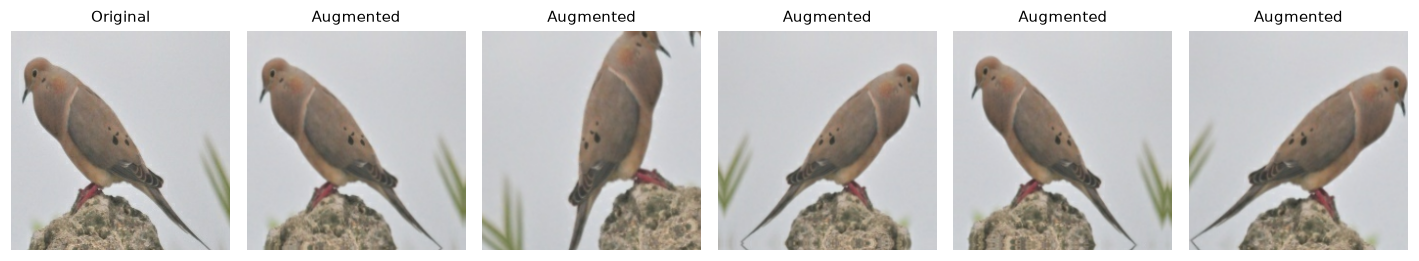

Epoch 1/40


38/38 - 10s - 261ms/step - accuracy: 0.1746 - loss: 2.2019 - val_accuracy: 0.2617 - val_loss: 2.0608


Epoch 2/40


38/38 - 8s - 215ms/step - accuracy: 0.2640 - loss: 1.9826 - val_accuracy: 0.2422 - val_loss: 1.9731


Epoch 3/40


38/38 - 8s - 215ms/step - accuracy: 0.3108 - loss: 1.8583 - val_accuracy: 0.3477 - val_loss: 1.8508


... (47 outputs left out)

38/38 - 11s - 283ms/step - accuracy: 0.6048 - loss: 1.0973 - val_accuracy: 0.4961 - val_loss: 1.5513


Epoch 28/40


38/38 - 11s - 278ms/step - accuracy: 0.6132 - loss: 1.0667 - val_accuracy: 0.4805 - val_loss: 1.6636


2. CNN + augmentation: validation {'accuracy': 0.555, 'precision': 0.581, 'recall': 0.557, 'F1': 0.558, 'ROC-AUC': 0.904, 'epochs': 28, 'minutes': 5.0, 'trainable_weights': 242122}


In [6]:
def augmentation():
    return keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.1),
                             layers.RandomZoom(0.1), layers.RandomContrast(0.2)], name="augmentation")


sample = next(iter(ds224["train"].unbatch().take(1)))[0]
aug = augmentation()
fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
axes[0].imshow(sample.numpy().astype("uint8")); axes[0].set_title("Original", fontsize=10)
for ax in axes[1:]:
    ax.imshow(np.clip(aug(sample[None], training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title("Augmented", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "augmentation_examples.png", bbox_inches="tight"); plt.show()

keras.utils.set_random_seed(SEED)
cnn_aug = fit("2. CNN + augmentation", small_cnn([augmentation()]), ds128, epochs=40, lr=1e-3, patience=6)

**What happened:** augmentation **lowered** validation macro F1 from **0.608 to 0.558**. The rubric asks us to report steps that didn't help, so here it is. Our explanation: with only ~120 photos per bird and ~30 epochs, a small CNN learning from scratch has a hard enough time learning the birds; adding random changes makes the task harder still, and it needs much longer training to benefit. Its final epoch shows train accuracy 61% vs. validation 48%, so it hadn't settled.

## 6. Step 3: transfer learning with MobileNetV2 (frozen)

**Why transfer learning:** with only ~120 photos per bird, a CNN from scratch has to learn what edges, feathers and eyes look like from very little data. MobileNetV2 has already learned those general visual features from 1.4 million ImageNet photos (which include many bird categories). We **remove its 1,000-class output layer, freeze all its layers**, and train only a new 10-class head.

**Why MobileNetV2 specifically:** it's small and fast (designed for phones), so it trains on a laptop CPU in minutes. It also needs its own preprocessing: full 224 px images with pixels scaled to −1…1.

**Strength:** strong features from very little data. **Limitation:** it assumes features learned on ImageNet transfer to our photos, and it inherits ImageNet's biases.

In [7]:
keras.utils.set_random_seed(SEED)
base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input((224, 224, 3))
x = augmentation()(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)            # training=False keeps BatchNorm statistics fixed, even when fine-tuning
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax", name="head")(x)
tl = keras.Model(inputs, outputs, name="mobilenetv2_birds")

tl = fit("3. MobileNetV2 frozen", tl, ds224, epochs=15, lr=1e-3, patience=4)
frozen_weights = tl.get_weights()   # starting point for every fine-tuning run below

Epoch 1/15


38/38 - 31s - 812ms/step - accuracy: 0.5397 - loss: 1.3904 - val_accuracy: 0.8359 - val_loss: 0.6944


Epoch 2/15


38/38 - 24s - 635ms/step - accuracy: 0.8521 - loss: 0.5175 - val_accuracy: 0.9180 - val_loss: 0.3910


Epoch 3/15


38/38 - 18s - 464ms/step - accuracy: 0.9031 - loss: 0.3537 - val_accuracy: 0.9219 - val_loss: 0.3044


... (21 outputs left out)

38/38 - 15s - 407ms/step - accuracy: 0.9699 - loss: 0.1038 - val_accuracy: 0.9531 - val_loss: 0.1641


Epoch 15/15


38/38 - 16s - 432ms/step - accuracy: 0.9557 - loss: 0.1219 - val_accuracy: 0.9336 - val_loss: 0.1913


3. MobileNetV2 frozen: validation {'accuracy': 0.953, 'precision': 0.963, 'recall': 0.955, 'F1': 0.956, 'ROC-AUC': 0.998, 'epochs': 15, 'minutes': 4.3, 'trainable_weights': 12810}


**What this shows:** transfer learning is the big jump: validation macro F1 goes from **0.608 (baseline) to 0.956**, while training only **12,810 weights** (just the new output layer) instead of 242,122. The pretrained features already "know" feathers, beaks and eyes from ImageNet.

### Step 3b: is augmentation still worth it with transfer learning?

Augmentation **hurt** the small CNN (step 2), so we check whether it helps MobileNetV2 before keeping it. This is the same model as step 3 with the augmentation layer removed.

In [8]:
keras.utils.set_random_seed(SEED)
base_noaug = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_noaug.trainable = False
inp = keras.Input((224, 224, 3))
z = keras.applications.mobilenet_v2.preprocess_input(inp)
z = base_noaug(z, training=False)
z = layers.GlobalAveragePooling2D()(z)
z = layers.Dropout(0.3)(z)
tl_noaug = keras.Model(inp, layers.Dense(len(CLASSES), activation="softmax", name="head")(z), name="mobilenetv2_noaug")
tl_noaug = fit("3b. MobileNetV2 frozen, no augmentation", tl_noaug, ds224, epochs=15, lr=1e-3, patience=4)

Epoch 1/15


38/38 - 17s - 438ms/step - accuracy: 0.5906 - loss: 1.3215 - val_accuracy: 0.8828 - val_loss: 0.5641


Epoch 2/15


38/38 - 13s - 335ms/step - accuracy: 0.8814 - loss: 0.4323 - val_accuracy: 0.9180 - val_loss: 0.3431


Epoch 3/15


38/38 - 13s - 339ms/step - accuracy: 0.9181 - loss: 0.2773 - val_accuracy: 0.9531 - val_loss: 0.2524


... (21 outputs left out)

38/38 - 13s - 338ms/step - accuracy: 0.9883 - loss: 0.0621 - val_accuracy: 0.9609 - val_loss: 0.1339


Epoch 15/15


38/38 - 13s - 341ms/step - accuracy: 0.9850 - loss: 0.0629 - val_accuracy: 0.9727 - val_loss: 0.1359


3b. MobileNetV2 frozen, no augmentation: validation {'accuracy': 0.961, 'precision': 0.967, 'recall': 0.964, 'F1': 0.964, 'ROC-AUC': 0.998, 'epochs': 15, 'minutes': 3.3, 'trainable_weights': 12810}


**What this shows:** without augmentation, MobileNetV2 scores slightly *higher* (validation F1 **0.964 vs. 0.956**, about 2 more images right out of 256). So augmentation didn't help either model here. A likely reason: the images are already clean, centered and similarly framed, so random flips, rotations and zooms mostly add noise. Because the gap is only about 2 images, we read it as "no benefit" rather than "harmful".

## 7. Steps 4–5: fine-tuning and hyperparameter tuning (validation only)

**Fine-tuning** unfreezes the top layers of MobileNetV2 so its bird-relevant features can adapt to our 10 species, using a tiny learning rate so the pretrained knowledge isn't overwritten.

**What we tune, and why it matters:**
- **Number of unfrozen layers (30 or 60):** more layers = more flexibility, but more risk of overfitting ~1,200 images.
- **Learning rate (1e-5 or 3e-5):** too high wrecks the pretrained weights; too low barely changes anything.

**Method:** a small **grid search**, 2 × 2 = 4 combinations. Each one starts from the same frozen model (step 3) and is scored on the **validation set only**. Step 4 is the default setting (30 layers, 1e-5); step 5 is whichever combination scores best on validation.

In [9]:
grid = [(30, 1e-5), (30, 3e-5), (60, 1e-5), (60, 3e-5)]
tuning, tuned_weights = [], {}
for n_layers, lr in grid:
    tl.set_weights(frozen_weights)
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    name = f"tune: top {n_layers} layers, lr {lr:g}"
    keras.utils.set_random_seed(SEED)
    fit(name, tl, ds224, epochs=8, lr=lr, patience=3)
    tuned_weights[name] = (n_layers, tl.get_weights())
    tuning.append({"unfrozen layers": n_layers, "learning rate": f"{lr:g}", "val F1": results[name]["F1"],
                   "val accuracy": results[name]["accuracy"], "epochs": results[name]["epochs"]})

tuning = pd.DataFrame(tuning).sort_values("val F1", ascending=False).round(3)
tuning

Epoch 1/8


38/38 - 27s - 707ms/step - accuracy: 0.8764 - loss: 0.3805 - val_accuracy: 0.9570 - val_loss: 0.1541


Epoch 2/8


38/38 - 19s - 495ms/step - accuracy: 0.9148 - loss: 0.2712 - val_accuracy: 0.9531 - val_loss: 0.1594


Epoch 3/8


38/38 - 20s - 520ms/step - accuracy: 0.9449 - loss: 0.1887 - val_accuracy: 0.9453 - val_loss: 0.1723


... (32 outputs left out)

Epoch 4/8


38/38 - 19s - 504ms/step - accuracy: 0.9691 - loss: 0.1007 - val_accuracy: 0.9062 - val_loss: 0.2236


tune: top 60 layers, lr 3e-05: validation {'accuracy': 0.938, 'precision': 0.947, 'recall': 0.937, 'F1': 0.939, 'ROC-AUC': 0.998, 'epochs': 4, 'minutes': 1.4, 'trainable_weights': 1539210}


,unfrozen layers,learning rate,val F1,val accuracy,epochs
0,30,1e-05,0.960,0.957,4
2,60,1e-05,0.955,0.953,4
3,60,3e-05,0.939,0.938,4
1,30,3e-05,0.931,0.930,8


**What this shows:** fine-tuning did **not** beat the frozen model. The best combination (top 30 layers, learning rate 1e-5, validation F1 **0.960**) is the same as the default, so **tuning changed nothing**. The larger learning rate (3e-5) hurt (0.931–0.939). Early stopping ended most runs after 4 epochs, which means validation loss started rising after the first epoch: the frozen features were already good, and with ~1,200 training images the extra flexibility (1.5 million trainable weights) mostly overfits.

In [10]:
default = "tune: top 30 layers, lr 1e-05"
best_cfg = max(tuned_weights, key=lambda k: results[k]["F1"])
results["4. Fine-tuned (default)"] = results[default]; test_probs["4. Fine-tuned (default)"] = test_probs[default]
results["5. Fine-tuned (tuned)"] = results[best_cfg]; test_probs["5. Fine-tuned (tuned)"] = test_probs[best_cfg]
print("Default:", default, "-> val F1", round(results[default]["F1"], 3))
print("Best on validation:", best_cfg, "-> val F1", round(results[best_cfg]["F1"], 3))



Default: tune: top 30 layers, lr 1e-05 -> val F1 0.96
Best on validation: tune: top 30 layers, lr 1e-05 -> val F1 0.96


## 8. Comparing every step on the validation set (this is what we choose with)

In [11]:
steps = ["0. Majority guess", "1. Baseline CNN", "2. CNN + augmentation", "3. MobileNetV2 frozen",
         "3b. MobileNetV2 frozen, no augmentation", "4. Fine-tuned (default)", "5. Fine-tuned (tuned)"]
val_table = pd.DataFrame({s: results[s] for s in steps}).T[["accuracy", "precision", "recall", "F1", "ROC-AUC", "epochs", "minutes"]]
val_table[["accuracy", "precision", "recall", "F1", "ROC-AUC"]] = val_table[["accuracy", "precision", "recall", "F1", "ROC-AUC"]].astype(float).round(3)
val_table

,accuracy,precision,recall,F1,ROC-AUC,epochs,minutes
0. Majority guess,0.125,0.012,0.100,0.022,0.500,NaN,NaN
1. Baseline CNN,0.609,0.628,0.614,0.608,0.939,30.0,3.7
2. CNN + augmentation,0.555,0.581,0.557,0.558,0.904,28.0,5.0
3. MobileNetV2 frozen,0.953,0.963,0.955,0.956,0.998,15.0,4.3
"3b. MobileNetV2 frozen, no augmentation",0.961,0.967,0.964,0.964,0.998,15.0,3.3
4. Fine-tuned (default),0.957,0.963,0.959,0.960,0.998,4.0,1.4
5. Fine-tuned (tuned),0.957,0.963,0.959,0.960,0.998,4.0,1.4


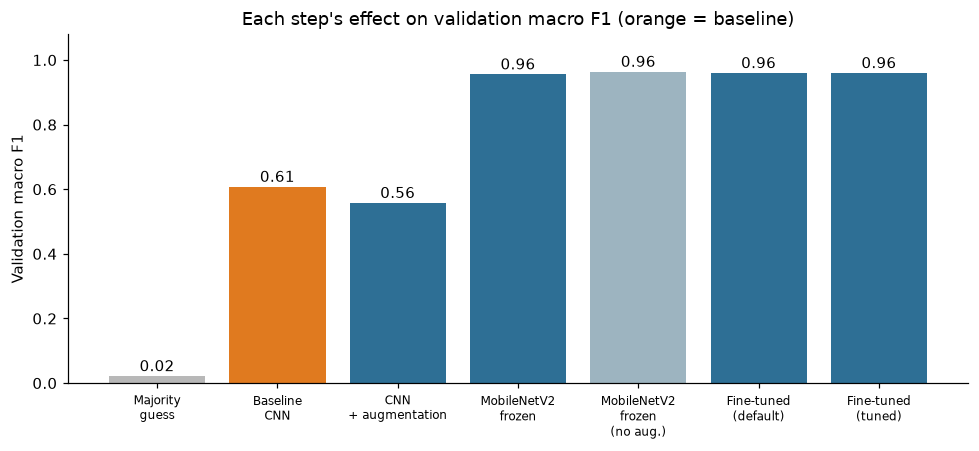

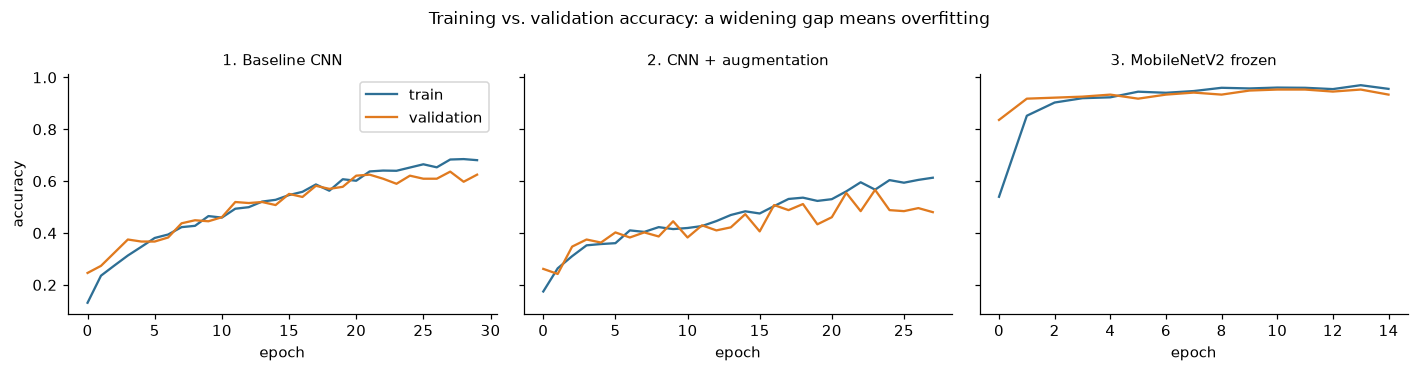

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.2))
vals = val_table.F1.astype(float).values
colors = ["#B8B8B8", "#E07A1F", "#2E6F95", "#2E6F95", "#9DB4C0", "#2E6F95", "#2E6F95"]
ax.bar(range(len(steps)), vals, color=colors)
for i, v in enumerate(vals):
    ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=10)
ax.set_xticks(range(len(steps)))
ax.set_xticklabels([s.split(". ", 1)[1].replace(", no augmentation", "\n(no aug.)").replace(" ", "\n", 1) for s in steps], fontsize=8)
ax.set_ylabel("Validation macro F1"); ax.set_ylim(0, 1.08)
ax.set_title("Each step's effect on validation macro F1 (orange = baseline)")
plt.tight_layout(); plt.savefig(FIG / "improvement_ladder.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, name in zip(axes, ["1. Baseline CNN", "2. CNN + augmentation", "3. MobileNetV2 frozen"]):
    h = histories[name]
    ax.plot(h["accuracy"], label="train", color="#2E6F95"); ax.plot(h["val_accuracy"], label="validation", color="#E07A1F")
    ax.set_title(name, fontsize=10); ax.set_xlabel("epoch")
axes[0].set_ylabel("accuracy"); axes[0].legend()
plt.suptitle("Training vs. validation accuracy: a widening gap means overfitting", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "training_curves.png", bbox_inches="tight"); plt.show()

**Selection rule (decided before looking at test scores):** pick the highest **validation macro F1**. If several models are within 0.005 of the best, which is less than one image out of 256, treat them as tied and keep the **simplest** one (fewest trained weights), because extra complexity that doesn't improve validation isn't justified.

In [13]:
cand = val_table.loc[steps[1:]].copy()
cand["F1"] = cand.F1.astype(float)
cand["trainable_weights"] = [results[s].get("trainable_weights", np.nan) for s in cand.index]
tied = cand[cand.F1 >= cand.F1.max() - 0.005]
final_name = tied.sort_values("trainable_weights").index[0]
print("Within 0.005 of the best validation F1:")
print(tied[["F1", "trainable_weights"]])
print("\nFinal model:", final_name)

# put the chosen model's weights in place (used for Grad-CAM, saving and the upload demo)
if final_name.startswith("3b"):
    final_model, final_base = tl_noaug, base_noaug
else:
    final_model, final_base = tl, base
    if final_name.startswith("3."):
        base.trainable = False
        tl.set_weights(frozen_weights)
    else:
        key = best_cfg if final_name.startswith("5") else default
        n_layers, w = tuned_weights[key]
        base.trainable = True
        for layer in base.layers[:-n_layers]:
            layer.trainable = False
        tl.set_weights(w)
check = scores(y["val"], final_model.predict(ds224["val"], verbose=0))["F1"]
assert abs(check - results[final_name]["F1"]) < 1e-6, "weights don't match the chosen model"
final_model.save(MODELS / "final_bird_model.keras")
print("Saved; validation F1 re-checked:", round(check, 3))

Within 0.005 of the best validation F1:
                                            F1  trainable_weights
3b. MobileNetV2 frozen, no augmentation  0.964              12810
4. Fine-tuned (default)                  0.960            1539210
5. Fine-tuned (tuned)                    0.960            1539210

Final model: 3b. MobileNetV2 frozen, no augmentation


Saved; validation F1 re-checked: 0.964


**Final model: MobileNetV2, frozen, without augmentation.** It has the highest validation macro F1 (**0.964**) *and* the fewest trained weights, so the tie rule wasn't even needed. It's also the simplest transfer-learning model we tried.

## 9. Final evaluation on the held-out test set

Every model is now scored on the same 257 test images. The final model was already chosen above using validation only; the test scores **report** performance and are not used to choose.

In [14]:
test_table = pd.DataFrame({s: scores(y["test"], test_probs[s]) for s in steps}).T.round(3)
test_table

,accuracy,precision,recall,F1,ROC-AUC
0. Majority guess,0.125,0.012,0.100,0.022,0.500
1. Baseline CNN,0.685,0.717,0.686,0.679,0.957
2. CNN + augmentation,0.556,0.588,0.552,0.559,0.923
3. MobileNetV2 frozen,0.934,0.948,0.937,0.936,0.999
"3b. MobileNetV2 frozen, no augmentation",0.961,0.964,0.964,0.964,0.999
4. Fine-tuned (default),0.953,0.958,0.955,0.955,0.999
5. Fine-tuned (tuned),0.953,0.958,0.955,0.955,0.999


**What this shows:** on the 257 held-out test images, the final model gets **96.1% accuracy and macro F1 0.964**, vs. **0.679** for the baseline CNN and **0.022** for guessing. Test scores line up closely with validation scores for every model (e.g., final model 0.964 on both), which suggests our validation-based choices were not overfit to the validation set.

*One honest note:* the fine-tuned model also scores 0.955 on test, close to the final model. We did not, and should not, re-pick a model based on test results.

In [15]:
prob = test_probs[final_name]
pred = prob.argmax(1)
print(classification_report(y["test"], pred, target_names=CLASSES, digits=3))

                      precision    recall  f1-score   support

      Common Grackle      0.929     0.929     0.929        28
                Crow      0.923     0.923     0.923        26
           Green Jay      1.000     1.000     1.000        25
       Mourning Dove      1.000     0.960     0.980        25
   Northern Cardinal      1.000     1.000     1.000        25
Northern Mockingbird      1.000     1.000     1.000        22
 Red Shouldered Hawk      0.923     0.889     0.906        27
     Red Tailed Hawk      0.909     0.938     0.923        32
          Roadrunner      1.000     1.000     1.000        26
           Rock Dove      0.955     1.000     0.977        21

            accuracy                          0.961       257
           macro avg      0.964     0.964     0.964       257
        weighted avg      0.961     0.961     0.961       257



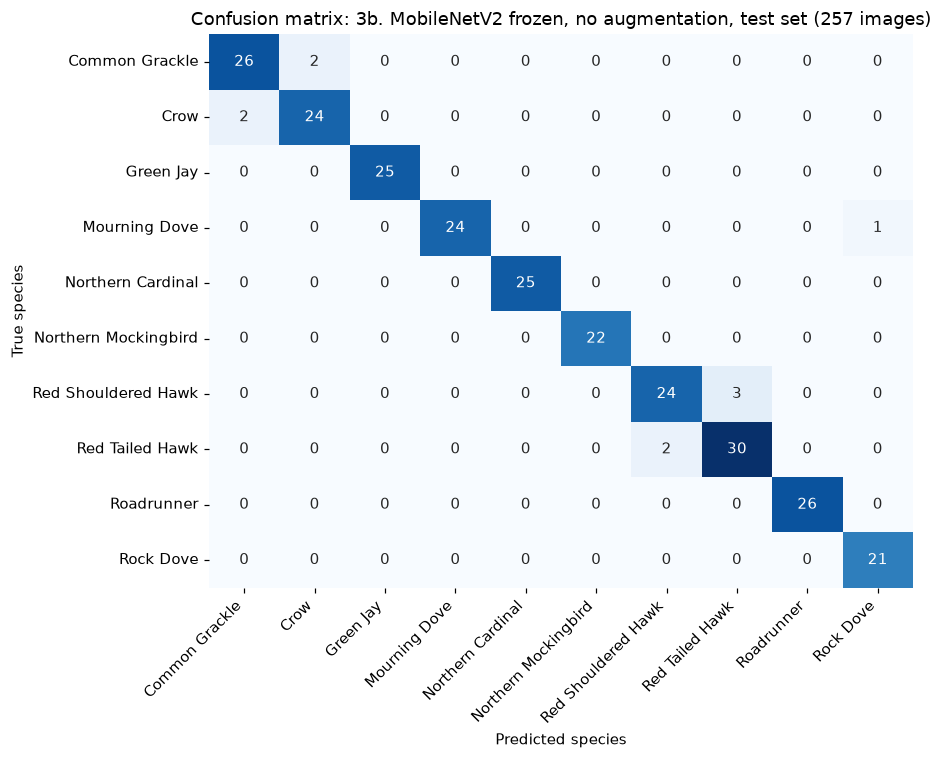

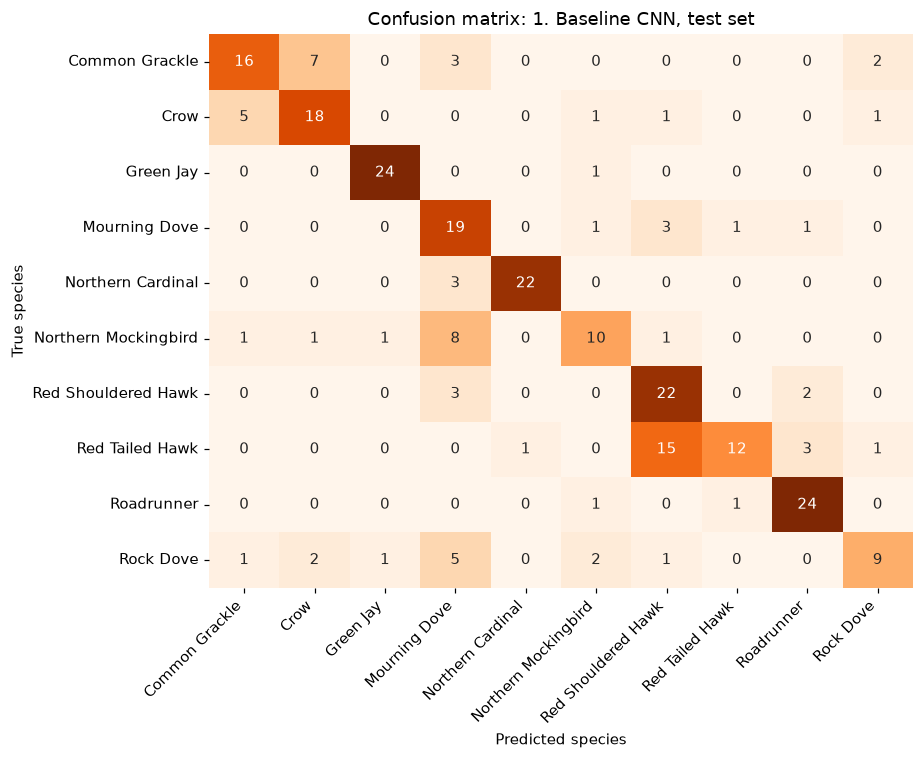

In [16]:
cm = confusion_matrix(y["test"], pred)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel("Predicted species"); ax.set_ylabel("True species")
ax.set_title(f"Confusion matrix: {final_name}, test set (257 images)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(FIG / "confusion_matrix.png", bbox_inches="tight"); plt.show()

base_pred = test_probs["1. Baseline CNN"].argmax(1)
cm_b = confusion_matrix(y["test"], base_pred)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm_b, annot=True, fmt="d", cmap="Oranges", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel("Predicted species"); ax.set_ylabel("True species")
ax.set_title("Confusion matrix: 1. Baseline CNN, test set")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(FIG / "confusion_matrix_baseline.png", bbox_inches="tight"); plt.show()

**What this shows:** almost everything sits on the diagonal. The only off-diagonal cells are inside the lookalike pairs: **Red-shouldered ↔ Red-tailed Hawk (5)**, **Crow ↔ Common Grackle (4)** and **Mourning ↔ Rock Dove (1)**. The baseline CNN (orange matrix) made 81 mistakes spread across many species.

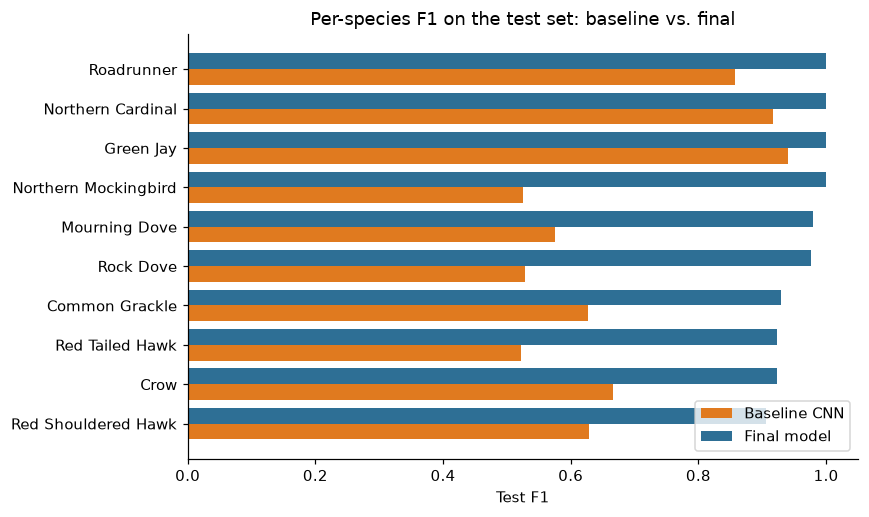

,baseline F1,final F1
Red Shouldered Hawk,0.629,0.906
Crow,0.667,0.923
Red Tailed Hawk,0.522,0.923
Common Grackle,0.627,0.929
Rock Dove,0.529,0.977
Mourning Dove,0.576,0.980
Northern Mockingbird,0.526,1.000
Green Jay,0.941,1.000
Northern Cardinal,0.917,1.000
Roadrunner,0.857,1.000


In [17]:
per_class = pd.DataFrame({"baseline F1": f1_score(y["test"], base_pred, average=None),
                          "final F1": f1_score(y["test"], pred, average=None)}, index=CLASSES).round(3)
per_class = per_class.sort_values("final F1")
fig, ax = plt.subplots(figsize=(8, 4.8))
ypos = np.arange(len(per_class))
ax.barh(ypos - 0.2, per_class["baseline F1"], height=0.4, color="#E07A1F", label="Baseline CNN")
ax.barh(ypos + 0.2, per_class["final F1"], height=0.4, color="#2E6F95", label="Final model")
ax.set_yticks(ypos); ax.set_yticklabels(per_class.index); ax.set_xlim(0, 1.05)
ax.set_xlabel("Test F1"); ax.set_title("Per-species F1 on the test set: baseline vs. final"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "per_class_f1.png", bbox_inches="tight"); plt.show()
per_class

**What this shows:** every species improves over the baseline. Four species are perfect on test (Northern Cardinal, Green Jay, Roadrunner, Northern Mockingbird); the lowest are the two hawks and the black birds (F1 0.91–0.93), exactly the pairs we expected to be hard.

## 10. Error analysis: were the mistakes inside the lookalike pairs?

In [18]:
pairs = [("Mourning Dove", "Rock Dove"), ("Red Tailed Hawk", "Red Shouldered Hawk"), ("Crow", "Common Grackle")]
pair_of = {}
for a, b in pairs:
    pair_of[idx[a]], pair_of[idx[b]] = idx[b], idx[a]


def error_split(p):
    wrong = p != y["test"]
    inside = np.array([pair_of.get(t) == q for t, q in zip(y["test"], p)])
    return {"mistakes": int(wrong.sum()), "inside a lookalike pair": int((wrong & inside).sum()),
            "other mistakes": int((wrong & ~inside).sum())}


errors = pd.DataFrame({"1. Baseline CNN": error_split(base_pred), final_name: error_split(pred)}).T
errors

,mistakes,inside a lookalike pair,other mistakes
1. Baseline CNN,81,32,49
"3b. MobileNetV2 frozen, no augmentation",10,10,0


**What this shows:** this answers objective 4. **All 10 of the final model's mistakes are inside a lookalike pair, and none are "random"**. The baseline CNN made 81 mistakes, and 49 of them were outside the pairs (e.g., confusing very different birds).

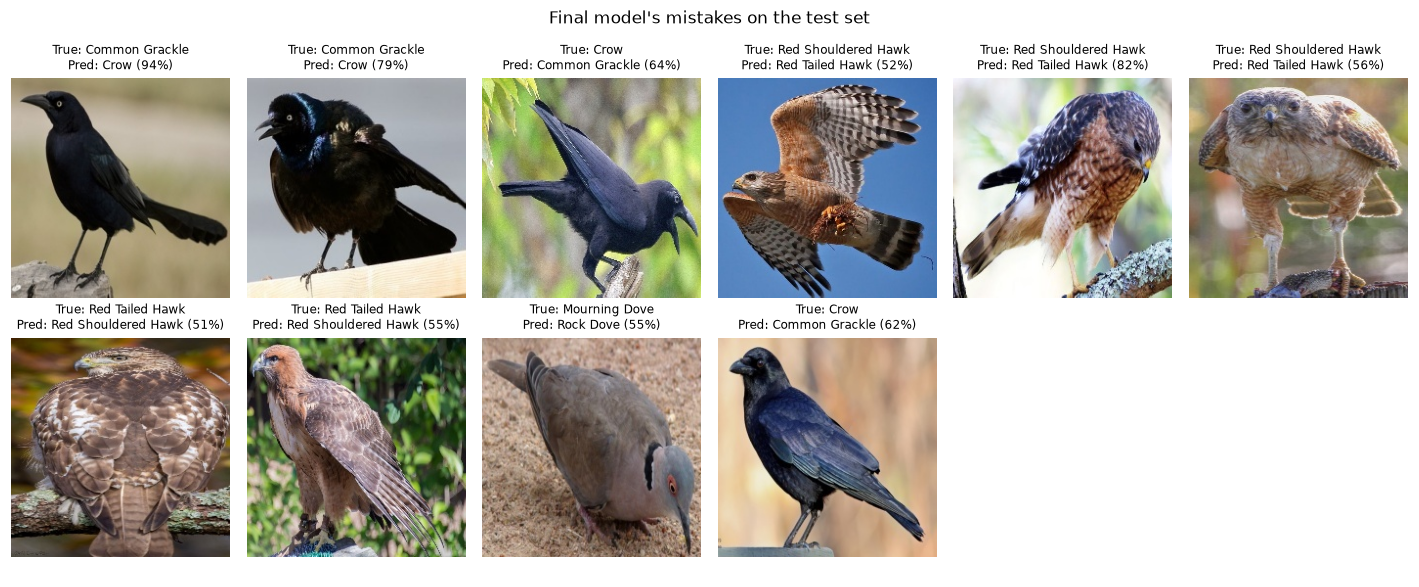

In [19]:
test_df = df[df.split == "test"].reset_index(drop=True)
mis = np.where(pred != y["test"])[0][:12]
if len(mis):
    cols = 6
    rows = int(np.ceil(len(mis) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 2.7 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, mis):
        ax.imshow(plt.imread(test_df.path[i]))
        ax.set_title(f"True: {CLASSES[y['test'][i]]}\nPred: {CLASSES[pred[i]]} ({prob[i].max():.0%})", fontsize=8)
    plt.suptitle("Final model's mistakes on the test set", fontsize=11)
    plt.tight_layout(); plt.savefig(FIG / "mistakes.png", bbox_inches="tight"); plt.show()
else:
    print("No mistakes on the test set.")

**What this shows:** the mistakes are understandable. Hawks photographed from behind or in flight hide the chest and tail colors that separate the two species, and grackles in poor light lose their purple sheen and look like crows. **7 of the 10 mistakes had confidence under 65%**, so the model is usually unsure when it's wrong; a real app could say "not sure" below a threshold. The mislabeled-looking "Mourning Dove" (it has a black neck ring like a collared dove) also hints at some **label noise** in the web-collected data.

## 11. What is the model looking at? (Grad-CAM)

Notebook 1 found that hawks are usually photographed against blue sky. If the model learned *"sky → hawk"*, it would be using a **shortcut** instead of the bird. Grad-CAM colors the parts of the image that pushed the model toward its prediction: **red = most important**.

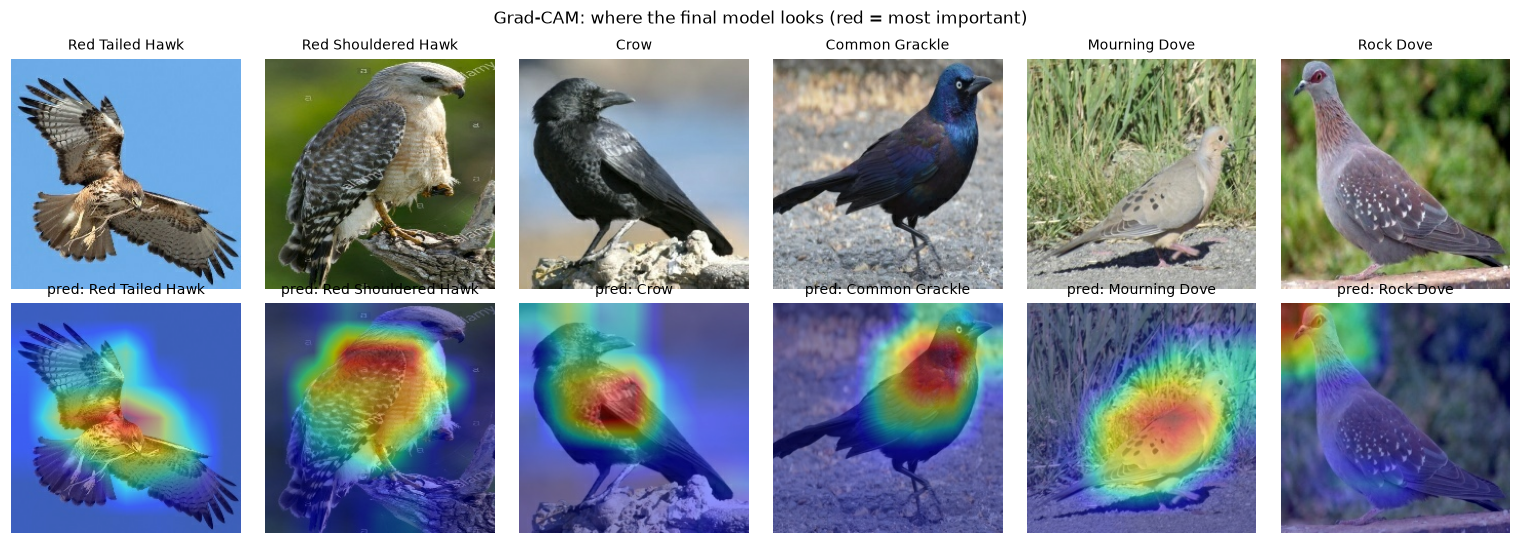

In [20]:
head = final_model.get_layer("head")


def gradcam(img_uint8):
    x = keras.applications.mobilenet_v2.preprocess_input(tf.cast(img_uint8[None], tf.float32))
    with tf.GradientTape() as tape:
        conv = final_base(x, training=False)    # last convolution output: 7 x 7 x 1280
        tape.watch(conv)
        p = head(tf.reduce_mean(conv, axis=(1, 2)))
        k = int(tf.argmax(p[0]))
        score = p[:, k]
    g = tape.gradient(score, conv)
    w = tf.reduce_mean(g, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (224, 224))[..., 0].numpy(), k


show = ["Red Tailed Hawk", "Red Shouldered Hawk", "Crow", "Common Grackle", "Mourning Dove", "Rock Dove"]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for c, sp in enumerate(show):
    i = test_df.index[test_df.species == sp][0]
    img = tf.io.decode_jpeg(tf.io.read_file(test_df.path[i]), channels=3)
    cam, k = gradcam(img)
    axes[0, c].imshow(img.numpy()); axes[0, c].set_title(sp, fontsize=9)
    axes[1, c].imshow(img.numpy()); axes[1, c].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, c].set_title(f"pred: {CLASSES[k]}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Grad-CAM: where the final model looks (red = most important)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "gradcam.png", bbox_inches="tight"); plt.show()

**What this shows:** for most birds the heat sits **on the bird's body**: the hawk's chest and tail, the crow's body, the grackle's head and neck. This is the plumage that actually separates these species. One exception: for the "Rock Dove" example the model focused on the top-left corner. That photo also looks like a *speckled pigeon* rather than a rock dove, another possible label-noise case.

In [21]:
# Quantify it: what share of the heatmap's weight falls in the image's outer frame (mostly background)?
frame = np.ones((224, 224), bool); frame[32:-32, 32:-32] = False
share = []
for i in range(len(test_df)):
    img = tf.io.decode_jpeg(tf.io.read_file(test_df.path[i]), channels=3)
    cam, _ = gradcam(img)
    share.append(cam[frame].sum() / (cam.sum() + 1e-8))
test_df["cam_on_border"] = share
print(f"Outer frame = {frame.mean():.0%} of the image area")
test_df.groupby("species").cam_on_border.mean().sort_values().round(3)

Outer frame = 49% of the image area


species
Northern Mockingbird    0.170
Green Jay               0.225
Red Shouldered Hawk     0.229
Crow                    0.242
Red Tailed Hawk         0.268
Northern Cardinal       0.276
Roadrunner              0.300
Mourning Dove           0.331
Common Grackle          0.341
Rock Dove               0.342
Name: cam_on_border, dtype: float32

**What this shows:** the outer frame covers 49% of the image, but it receives only **17–34%** of the heatmap's weight for every species. Even for hawks, the "sky" species from notebook 1, it's 23–27%. So the final model mostly looks at the **center, where the bird is**, rather than relying on the sky background. This reduces, though doesn't fully rule out, the shortcut-learning concern.

## 12. Save the numbers for the slides

In [22]:
out = {"classes": CLASSES, "final_model": final_name, "best_tuning_config": best_cfg,
       "validation": val_table.astype(object).to_dict(orient="index"), "test": test_table.to_dict(orient="index"),
       "tuning_grid": tuning.to_dict(orient="records"), "per_class_test_f1": per_class.to_dict(orient="index"),
       "errors": errors.to_dict(orient="index"),
       "gradcam_border_share": test_df.groupby("species").cam_on_border.mean().round(3).to_dict()}
Path("../reports/results.json").write_text(json.dumps(out, indent=2, default=float))
print("saved ../reports/results.json")

saved ../reports/results.json


## 13. Optional: try your own photo (upload page)

Set `RUN_DEMO = True` and run the cell to open a small web page where you can upload any bird photo and see the model's top 3 guesses.

In [23]:
RUN_DEMO = False

if RUN_DEMO:
    import gradio as gr

    def classify(image):
        x = tf.image.resize(np.array(image.convert("RGB")), (224, 224))[None]
        p = final_model.predict(x, verbose=0)[0]
        return {CLASSES[i]: float(p[i]) for i in range(len(CLASSES))}

    gr.Interface(fn=classify, inputs=gr.Image(type="pil"), outputs=gr.Label(num_top_classes=3),
                 title="Which Texas Bird Is It?",
                 description="Upload a photo of one of our 10 species.").launch(inbrowser=True)

## 14. Summary: answering our objectives

| Objective | Answer |
|---|---|
| 1. Baseline | Simple CNN with minimum preprocessing: **validation macro F1 0.608**, test 0.679. Majority guess: 0.022. |
| 2. Step-by-step improvement | **Transfer learning** gave the whole gain (0.608 → 0.956 validation). Augmentation **did not help** (CNN 0.608 → 0.558; MobileNetV2 0.956 vs. 0.964 without). Fine-tuning and tuning **did not help** (best 0.960 = the default setting). |
| 3. Final evaluation (test, used once) | **MobileNetV2, frozen, no augmentation: 96.1% accuracy, macro F1 0.964, ROC-AUC 0.999**, on 257 images it never trained on. |
| 4. Lookalikes and backgrounds | **All 10 test mistakes are inside the lookalike pairs** (5 hawks, 4 crow/grackle, 1 dove). Grad-CAM shows the model mostly looks at the bird, not the sky. |

**Main takeaway:** with only ~120 photos per species, *reusing* a network trained on millions of photos matters far more than anything we tuned ourselves. The remaining errors are the hard, genuinely similar species: the same pairs a beginner birder would mix up.

**What we would not claim:** these photos are clean, cropped and centered, and many come from the web. 96% here does **not** mean 96% on blurry backyard or camera-trap photos, or on species outside our 10. The model will always answer with one of the 10 birds, even for a photo of a penguin.